In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

PROCESSED_DIR = '/content/drive/MyDrive/football_project/data/processed'
MODELS_DIR = '/content/drive/MyDrive/football_project/models'
FIG_DIR = '/content/reports/figures'
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv(f'{PROCESSED_DIR}/players_clean.csv')
print("Форма:", df.shape)
print("Колонки:", list(df.columns))
df.head(3)

Mounted at /content/drive
Форма: (40374, 26)
Колонки: ['player_id', 'name', 'date_of_birth', 'position', 'sub_position', 'country_of_citizenship', 'foot', 'height_in_cm', 'current_club_id', 'current_club_name', 'current_club_domestic_competition_id', 'market_value_in_eur', 'highest_market_value_in_eur', 'goals', 'assists', 'appearances', 'minutes_played', 'yellow_cards', 'red_cards', 'competition_name', 'type', 'country_name', 'age', 'value_mln', 'age_group', 'league_label']


,player_id,name,date_of_birth,position,sub_position,country_of_citizenship,foot,height_in_cm,current_club_id,current_club_name,...,minutes_played,yellow_cards,red_cards,competition_name,type,country_name,age,value_mln,age_group,league_label
0,276,Sladan Peric,1982-04-15,Defender,Centre-Back,Denmark,Unknown,182.0,20100,FC Vestsjaelland,...,232.0,0.0,0.0,superliga,domestic_league,Denmark,44.6,0.20,37+,Denmark — superliga
1,691,Simon Rolfes,1982-01-21,Midfield,Defensive Midfield,Germany,left,191.0,15,Bayer 04 Leverkusen,...,8123.0,10.0,1.0,bundesliga,domestic_league,Germany,44.8,2.00,37+,Germany — bundesliga
2,992,Christian Weber,1983-09-15,Defender,Right-Back,Germany,right,175.0,38,Fortuna Düsseldorf,...,90.0,0.0,0.0,bundesliga,domestic_league,Germany,43.2,0.05,37+,Germany — bundesliga


In [2]:
# Целевая переменная — логарифм цены
df['target'] = np.log1p(df['market_value_in_eur'])

print("Статистика target (log1p):")
print(df['target'].describe().round(3))

Статистика target (log1p):
count    40374.000
mean        12.707
std          1.521
min          9.210
25%         11.513
50%         12.525
75%         13.528
max         19.114
Name: target, dtype: float64


Почему логарифм цены:

Распределение стоимости сильно скошено вправо: большинство игроков дешевле 1 млн €,
единицы - дороже 100 млн €. Если прогнозировать цену напрямую, модель будет
зацикливаться на дорогих игроках и плохо предсказывать дешёвых.

Логарифм `log1p(price)` сжимает большие значения и растягивает маленькие:
- 100 000 € => log1p примерно 11.5
- 1 000 000 € => log1p примерно 13.8
- 100 000 000 € => log1p примерно 18.4

После обучения переведём предсказания обратно через `expm1(pred)` и будем
считать метрики в евро (MAE, RMSE), чтобы они были понятны.

In [3]:
# Числовые признаки
num_features = ['age', 'height_in_cm', 'goals', 'assists',
                'appearances', 'minutes_played',
                'yellow_cards', 'red_cards']

# Категориальные признаки
cat_features = ['position', 'sub_position',
                'country_of_citizenship', 'league_label']

# Явно исключаем
exclude_cols = ['player_id', 'name', 'date_of_birth',
                'market_value_in_eur',       # целевая в исходном виде
                'value_mln',                 # производная от целевой
                'highest_market_value_in_eur',
                'target',                    # наша целевая
                'age_group', 'value_category',  # производные от целевой/возраста
                'current_club_id', 'current_club_name',
                'current_club_domestic_competition_id',
                'competition_name', 'country_name',  # уже в league_label
                'foot']

print("Числовые признаки:", num_features)
print("Категориальные признаки:", cat_features)
print("Исключено:", len(exclude_cols), "колонок")

Числовые признаки: ['age', 'height_in_cm', 'goals', 'assists', 'appearances', 'minutes_played', 'yellow_cards', 'red_cards']
Категориальные признаки: ['position', 'sub_position', 'country_of_citizenship', 'league_label']
Исключено: 15 колонок


Что исключаем и почему:

- `highest_market_value_in_eur` - это будущий пик цены, модель
  не должна его видеть.
- `market_value_in_eur`, `value_mln` - целевая переменная в исходном виде.
- `player_id`, `name`, `date_of_birth` - идентификаторы, не признаки.
- `current_club_id`, `current_club_name` - слишком много категорий (сотни клубов),
  и они дублируют информацию из `league_label`.
- `age_group`, `value_category` - производные от возраста/цели.
- `competition_name`, `country_name` - уже объединены в `league_label`.

Признаки для модели: xисловые (8): возраст, рост, голы, передачи, матчи, минуты, жёлтые, красные.
Категориальные (4): позиция (широкая), позиция (детальная), гражданство, лига.

In [4]:
def reduce_categories(series, top_n=15, other_label='Other'):
    #Оставляем самые частые значения, остальные => other_label
    top = series.value_counts().head(top_n).index
    return series.where(series.isin(top), other_label)

for col in cat_features:
    before = df[col].nunique()
    df[col] = reduce_categories(df[col], top_n=15)
    after = df[col].nunique()
    print(f"{col}: {before} → {after} категорий")

position: 5 → 5 категорий
sub_position: 14 → 14 категорий
country_of_citizenship: 195 → 16 категорий
league_label: 32 → 16 категорий


Почему объединяем редкие категории:

В `country_of_citizenship` и `league_label` могут быть десятки уникальных
значений. Если закодировать все через one-hot, получим сотни колонок, и модель
начнёт переобучаться на редких категориях (например, игрок из Сан-Марино
с 1 матчем).

In [5]:
# One-hot для категориальных признаков
df_encoded = pd.get_dummies(df[cat_features], drop_first=True, dtype=int)

print("Форма после one-hot:", df_encoded.shape)
print("Колонки (первые 20):", list(df_encoded.columns)[:20])

Форма после one-hot: (40374, 47)
Колонки (первые 20): ['position_Defender', 'position_Goalkeeper', 'position_Midfield', 'position_Missing', 'sub_position_Central Midfield', 'sub_position_Centre-Back', 'sub_position_Centre-Forward', 'sub_position_Defensive Midfield', 'sub_position_Goalkeeper', 'sub_position_Left Midfield', 'sub_position_Left Winger', 'sub_position_Left-Back', 'sub_position_Right Midfield', 'sub_position_Right Winger', 'sub_position_Right-Back', 'sub_position_Second Striker', 'sub_position_Unknown', 'country_of_citizenship_Belgium', 'country_of_citizenship_Brazil', 'country_of_citizenship_Denmark']


In [6]:
#Собрать матрицу признаков
# Числовые +  категориальные
X = pd.concat([
    df[num_features].reset_index(drop=True),
    df_encoded.reset_index(drop=True)
], axis=1)

y = df['target'].reset_index(drop=True)

print("Форма X:", X.shape)
print("Форма y:", y.shape)
print("\nПропуски в X:", X.isna().sum().sum())
print("Пропуски в y:", y.isna().sum())
print("\nТипы колонок X:")
print(X.dtypes.value_counts())

Форма X: (40374, 55)
Форма y: (40374,)

Пропуски в X: 0
Пропуски в y: 0

Типы колонок X:
int64      47
float64     8
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)
print(f"Доля test: {len(X_test) / len(X) * 100:.1f}%")

Train: (32299, 55) (32299,)
Test:  (8075, 55) (8075,)
Доля test: 20.0%


In [8]:
# Масштабирование числовых признаков
from sklearn.preprocessing import StandardScaler

# Индексы числовых колонок (они идут первыми в X)
num_idx = list(range(len(num_features)))

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled.iloc[:, num_idx] = scaler.fit_transform(X_train.iloc[:, num_idx])
X_test_scaled.iloc[:, num_idx] = scaler.transform(X_test.iloc[:, num_idx])

print("До масштабирования (train, первые 3 числовых):")
print(X_train.iloc[:, :3].describe().loc[['mean', 'std']].round(2))
print("\nПосле масштабирования (train, первые 3 числовых):")
print(X_train_scaled.iloc[:, :3].describe().loc[['mean', 'std']].round(2))

До масштабирования (train, первые 3 числовых):
        age  height_in_cm  goals
mean  30.08        182.03   4.29
std    6.16          7.22  13.82

После масштабирования (train, первые 3 числовых):
      age  height_in_cm  goals
mean  0.0           0.0    0.0
std   1.0           1.0    1.0


In [9]:
# Сохраняем X, y, scaler и список колонок
X_train_scaled.to_csv(f'{PROCESSED_DIR}/X_train.csv', index=False)
X_test_scaled.to_csv(f'{PROCESSED_DIR}/X_test.csv', index=False)
y_train.to_csv(f'{PROCESSED_DIR}/y_train.csv', index=False)
y_test.to_csv(f'{PROCESSED_DIR}/y_test.csv', index=False)

import pickle
with open(f'{MODELS_DIR}/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

with open(f'{MODELS_DIR}/feature_names.pkl', 'wb') as f:
    pickle.dump(list(X.columns), f)

with open(f'{MODELS_DIR}/num_features.pkl', 'wb') as f:
    pickle.dump(num_features, f)

print("Сохранено:")
print("- X_train.csv, X_test.csv, y_train.csv, y_test.csv")
print("- scaler.pkl, feature_names.pkl, num_features.pkl")

Сохранено:
- X_train.csv, X_test.csv, y_train.csv, y_test.csv
- scaler.pkl, feature_names.pkl, num_features.pkl


- `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv` - чтобы этап
  (моделирование) не зависел от этого этапа и мог запускаться отдельно.
- `scaler.pkl` - нужен на этапе (предсказание), чтобы преобразовывать
  входные данные пользователя так же, как обучающие.
- `feature_names.pkl` - список колонок X. Нужен, чтобы при предсказании
  проверить, что порядок и состав признаков совпадает с обучением.
- `num_features.pkl` - список числовых признаков (для масштабирования при
  предсказании).

ИТОГОВЫЕ ФОРМЫ:
X_train: (32299, 55)
X_test:  (8075, 55)
y_train: (32299,)
y_test:  (8075,)
Всего признаков: 55


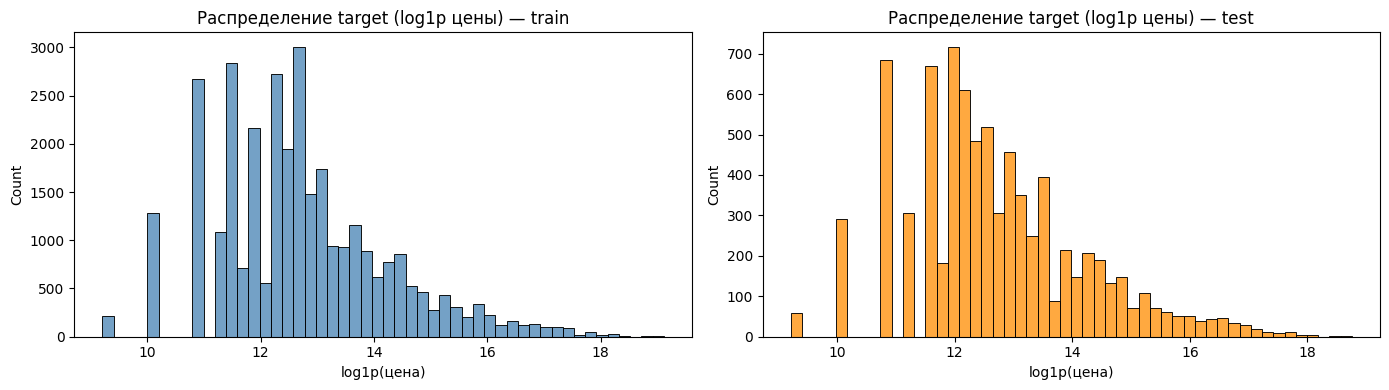

In [10]:
print("ИТОГОВЫЕ ФОРМЫ:")
print(f"X_train: {X_train_scaled.shape}")
print(f"X_test:  {X_test_scaled.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")
print(f"Всего признаков: {X_train_scaled.shape[1]}")


# Распределение target в train и test — должны быть похожи
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(y_train, bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Распределение target (log1p цены) — train')
axes[0].set_xlabel('log1p(цена)')

sns.histplot(y_test, bins=50, ax=axes[1], color='darkorange')
axes[1].set_title('Распределение target (log1p цены) — test')
axes[1].set_xlabel('log1p(цена)')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/09_target_distribution.png', dpi=150)
plt.show()

Что видим: распределения target в train и test похожи.
sразделение не перекосило выборку. Оба распределения близки к нормальному (после
лог-преобразования).